# Connectivity (Figure 8) — `duecker_ET_model`

Connectivity structure and postsynaptic behaviour of the network model.
Figures are written to `results/network_sim/connectivity/`.

| Manuscript figure | Section |
| --- | --- |
| Fig. 8b | Connectivity matrices |
| Fig. 8c | Space constant |
| Fig. 8d–f | Single-neuron connectivity heatmaps |
| Fig. 8g | Postsynaptic potentials (PSPs) |
| Not shown | Spike rasters when driving individual cell types |

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize
from matplotlib import patches
from matplotlib.gridspec import GridSpec
from matplotlib import colormaps

from hnn_core import duecker_ET_model, simulate_dipole
from hnn_core.cell import _get_gaussian_connection

from hnn_tuning import results_dir
from hnn_tuning.plot_utils import assign_color

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 6

figpth = results_dir('network_sim', 'connectivity')
os.makedirs(figpth, exist_ok=True)

cmap = colormaps['Set2']

net = duecker_ET_model()


def conn_space_constant(x, lamtha, inplane_distance):
    """Connection-weight profile for a given space constant (Campagnola 2022 ref)."""
    A = 0.1
    return A * np.exp(-(x / (lamtha * inplane_distance)) ** 2)


def delay_space_constant(x, lamtha, inplane_distance):
    """Connection-weight profile for a given space constant (Campagnola 2022 ref)."""
    A = 1
    return A / np.exp(-(x / (lamtha * inplane_distance)) ** 2)

## Fig. 8b, c — connectivity matrices + space constant

Excitatory (top) and inhibitory (bottom) synaptic-weight matrices, and the
distance-dependent connection weight (space constant) vs the Campagnola 2022
Gaussian.

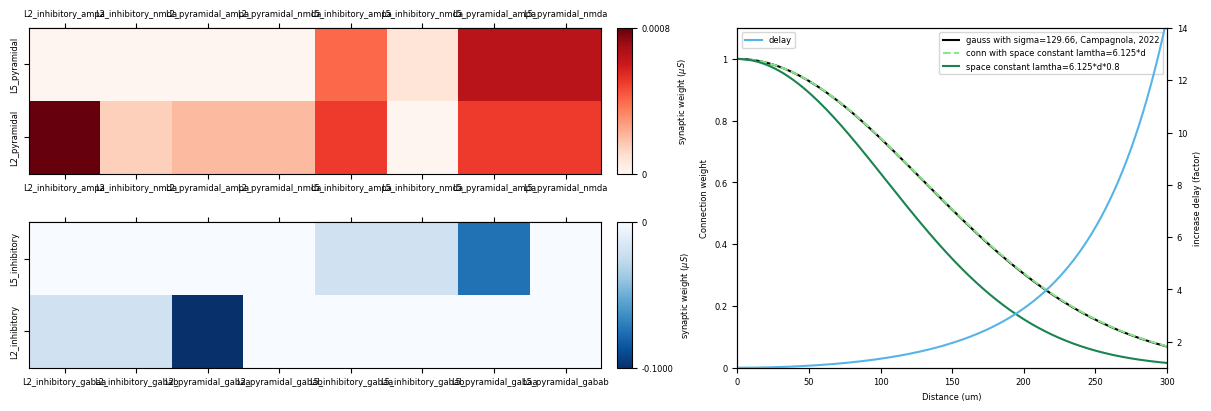

In [ ]:
net = duecker_ET_model()
lamtha1 = 6.125
lamtha2 = 6.125 * 0.8

targets = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
src_inh = ['L2_inhibitory', 'L5_inhibitory']
src_pyr = ['L2_pyramidal', 'L5_pyramidal']
E_receptors = ['ampa', 'nmda']
I_receptors = ['gabaa', 'gabab']

connectivity_data = dict()
for src in targets:
    connectivity_data[src] = dict()
    for conn in net.connectivity:
        if conn['src_type'] == src:
            t_type = conn['target_type']
            if connectivity_data[src].get(t_type) is None:
                connectivity_data[src][t_type] = dict()
            rec = conn['receptor']
            connectivity_data[src][t_type][rec] = conn['nc_dict']['A_weight']

conn_im_pyr = np.zeros((len(src_pyr), len(targets), 2))
conn_im_inh = np.zeros((len(src_inh), len(targets), 2))

xticklabels_pyr = []
for target in targets:
    for rec in E_receptors:
        xticklabels_pyr.append(f'{target}_{rec}')

for s, src in enumerate(src_pyr):
    for t, target in enumerate(targets):
        if connectivity_data[src].get(target) is not None:
            for i, rec in enumerate(E_receptors):
                if rec in connectivity_data[src][target]:
                    conn_im_pyr[s, t, i] = connectivity_data[src][target][rec]

xticklabels_inh = []
for target in targets:
    for rec in I_receptors:
        xticklabels_inh.append(f'{target}_{rec}')

for s, src in enumerate(src_inh):
    for t, target in enumerate(targets):
        if connectivity_data[src].get(target) is not None:
            for i, rec in enumerate(I_receptors):
                if rec in connectivity_data[src][target]:
                    conn_im_inh[s, t, i] = -connectivity_data[src][target][rec]

fig = plt.figure(figsize=(12, 4.), constrained_layout=True)
gs = GridSpec(2, 3, width_ratios=[1, 0.025, 0.75], figure=fig)
ax = [None] * 3
ax[0] = fig.add_subplot(gs[0, 0])
ax[1] = fig.add_subplot(gs[1, 0])
cax1 = fig.add_subplot(gs[0, 1])
cax2 = fig.add_subplot(gs[1, 1])
ax[2] = fig.add_subplot(gs[:, 2])

conn_im_inh = conn_im_inh.reshape(len(src_inh), len(targets) * 2)
conn_im_pyr = conn_im_pyr.reshape(len(src_pyr), len(targets) * 2)

norm_inh = Normalize(vmin=np.min(conn_im_inh), vmax=0)
norm_pyr = Normalize(vmin=0, vmax=np.max(conn_im_pyr))

im = ax[0].pcolormesh(conn_im_pyr, cmap='Reds', norm=norm_pyr)
ax[0].set_yticks(np.arange(.5, 2.5, 1))
ax[0].set_yticklabels(src_pyr, rotation='vertical', va='center')
ax[0].set_xticks(np.arange(0.5, 8.5, 1))
ax[0].set_xticklabels(xticklabels_pyr)
axxtw = ax[0].secondary_xaxis('top')
axxtw.set_xticks(np.arange(0.5, 8.5, 1))
axxtw.set_xticklabels(xticklabels_pyr)

cb2 = plt.colorbar(im, cax=cax1)
cb2.set_ticks([0, np.max(conn_im_pyr)])
cb2.set_ticklabels(['0', f'{np.max(conn_im_pyr):.4f}'])
cb2.set_label(r'synaptic weight ($\mu S$)')

im = ax[1].pcolormesh(conn_im_inh, cmap='Blues_r', norm=norm_inh)
ax[1].set_yticks(np.arange(.5, 2.5, 1))
ax[1].set_yticklabels(src_inh, rotation='vertical', va='center')
ax[1].set_xticks(np.arange(0.5, 8.5, 1))
ax[1].set_xticklabels(xticklabels_inh)
axxtw2 = ax[1].secondary_xaxis('top')
axxtw2.set_xticks(np.arange(0.5, 8.5, 1))
axxtw2.set_xticklabels([])

cb1 = plt.colorbar(im, cax=cax2)
cb1.set_ticks([np.min(conn_im_inh), 0])
cb1.set_ticklabels([f'{np.min(conn_im_inh):.4f}', '0'])
cb1.set_label(r'synaptic weight ($\mu S$)')

# space constant
x = np.linspace(0, 300, 1000)
y = conn_space_constant(x, lamtha1, 30)
y2 = conn_space_constant(x, lamtha2, 30)
d = delay_space_constant(x, lamtha1, 30)


ax[2].plot(x, 0.1 * np.exp(-x**2 / (2 * 129.66**2)), label='gauss with sigma=129.66, Campagnola, 2022', color='k')
ax[2].plot(x, y, linestyle='--', label='conn with space constant lamtha=6.125*d', color='#88e788')
ax[2].plot(x, y2, label='space constant lamtha=6.125*d*0.8', color='#198450')
ax[2].legend()
ax[2].set_xlabel('Distance (um)')
ax[2].set_ylabel('Connection weight')
ax[2].set_xlim([0, 300])
ax[2].set_ylim([0, 0.11])
ax[2].set_yticks([0, 0.02, 0.04, 0.06, 0.08, 0.1])
ax[2].set_yticklabels([0, 0.2, 0.4, 0.6, 0.8, 1])
ax2tw = ax[2].twinx()
ax2tw.plot(x, d, color='#56B4E9', label="delay")
ax2tw.set_ylabel("increase delay (factor)")
ax2tw.set_ylim([1, 14])
ax2tw.legend()

fig.savefig(figpth / 'conn_matrix_space_constant.png')
fig.savefig(figpth / 'conn_matrix_space_constant.pdf')
fig.savefig(figpth / 'conn_matrix_space_constant.svg')
plt.show()

## Fig. 8d–f — single-neuron connectivity heatmaps

Spatial spread of connection weight (Gaussian in-plane) for a reference cell at
three grid positions (bottom-left, centre, top-right), for E→E, E→I and I→I.

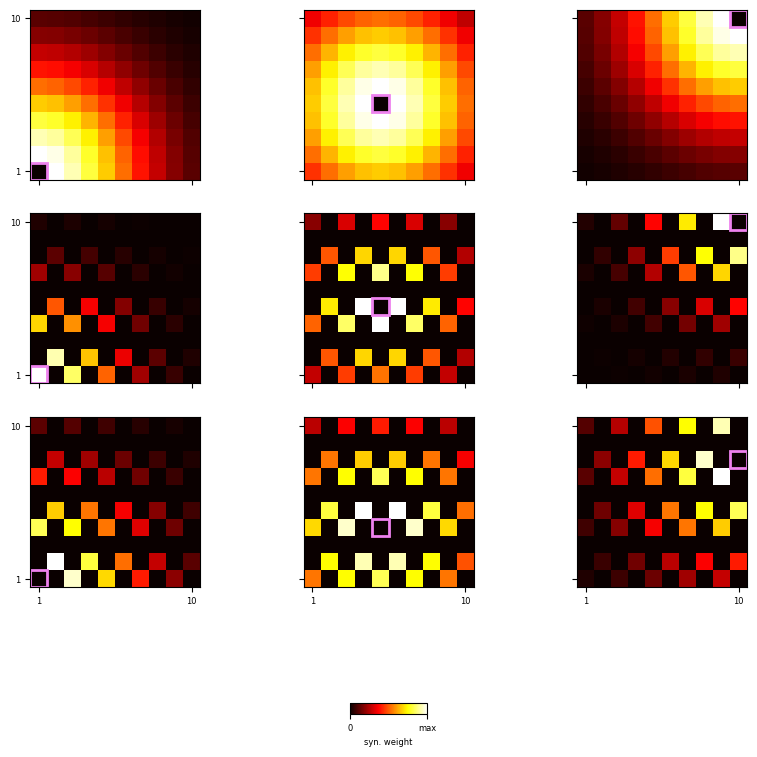

In [13]:
net = duecker_ET_model()

fig, ax = plt.subplots(3, 3, figsize=(10, 10), sharex=True, sharey=True)

# E-E
conn = net.connectivity[2]

pos_l5 = np.zeros((100, 3))
for p, pos in enumerate(net.pos_dict['L5_pyramidal']):
    pos_l5[p] = np.array(pos)

l5_gid = 170
ref_pos = net.pos_dict['L5_pyramidal'][int(l5_gid) - 170]
l5_center_conn_bl = np.zeros((10, 10))
for target_gid in conn["gid_pairs"][l5_gid]:
    if target_gid in net.gid_ranges['L5_pyramidal']:
        target_pos = net.pos_dict['L5_pyramidal'][int(target_gid - 170)]
        weight, _ = _get_gaussian_connection(ref_pos, target_pos, conn['nc_dict'], inplane_distance=net._inplane_distance)
        l5_center_conn_bl[int(target_pos[0]), int(target_pos[1])] = weight
ax[0, 0].imshow(l5_center_conn_bl, origin='lower', cmap='hot', vmin=0, vmax=np.max(l5_center_conn_bl))
ax[0, 0].add_patch(patches.Rectangle((ref_pos[0] - 0.5, ref_pos[1] - 0.5), 1, 1, fill=False, edgecolor='violet', linewidth=2))

l5_gid = 170 + 44
ref_pos = net.pos_dict['L5_pyramidal'][int(l5_gid) - 170]
l5_center_conn_c = np.zeros((10, 10))
for target_gid in conn["gid_pairs"][int(l5_gid)]:
    if target_gid in net.gid_ranges['L5_pyramidal']:
        target_pos = net.pos_dict['L5_pyramidal'][int(target_gid - 170)]
        weight, _ = _get_gaussian_connection(ref_pos, target_pos, conn['nc_dict'], inplane_distance=net._inplane_distance)
        l5_center_conn_c[int(target_pos[0]), int(target_pos[1])] = weight
ax[0, 1].imshow(l5_center_conn_c, origin='lower', cmap='hot', vmin=0, vmax=np.max(l5_center_conn_c))
ax[0, 1].add_patch(patches.Rectangle((ref_pos[0] - 0.5, ref_pos[1] - 0.5), 1, 1, fill=False, edgecolor='violet', linewidth=2))

l5_gid = 269
ref_pos = net.pos_dict['L5_pyramidal'][int(l5_gid) - 170]
l5_center_conn_tr = np.zeros((10, 10))
for target_gid in conn["gid_pairs"][l5_gid]:
    if target_gid in net.gid_ranges['L5_pyramidal']:
        target_pos = net.pos_dict['L5_pyramidal'][int(target_gid - 170)]
        weight, _ = _get_gaussian_connection(ref_pos, target_pos, conn['nc_dict'], inplane_distance=net._inplane_distance)
        l5_center_conn_tr[int(target_pos[0]), int(target_pos[1])] = weight
ax[0, 2].imshow(l5_center_conn_tr, origin='lower', cmap='hot', vmin=0, vmax=np.max(l5_center_conn_tr))
ax[0, 2].add_patch(patches.Rectangle((ref_pos[0] - 0.5, ref_pos[1] - 0.5), 1, 1, fill=False, edgecolor='violet', linewidth=2))

# E-I
conn = net.connectivity[-2]
for ax_col, l5_gid in zip(range(3), [170, 170 + 44, 269]):
    ref_pos = net.pos_dict['L5_pyramidal'][int(l5_gid) - 170]
    l5_center_conn_ei = np.zeros((10, 10))
    for target_gid in conn["gid_pairs"][l5_gid]:
        if target_gid in net.gid_ranges['L5_inhibitory']:
            target_pos = net.pos_dict['L5_inhibitory'][int(target_gid - 135)]
        weight, _ = _get_gaussian_connection(ref_pos, target_pos, conn['nc_dict'], inplane_distance=net._inplane_distance)
        l5_center_conn_ei[int(target_pos[0]), int(target_pos[1])] = weight
    ax[1, ax_col].imshow(l5_center_conn_ei, origin='lower', cmap='hot', vmin=0, vmax=np.max(l5_center_conn_ei))
    ax[1, ax_col].add_patch(patches.Rectangle((ref_pos[0] - 0.5, ref_pos[1] - 0.5), 1, 1, fill=False, edgecolor='violet', linewidth=2))

# I-I
conn = net.connectivity[16]
im = None
for ax_col, inh_gid in zip(range(3), [0, 15, 34]):
    ref_pos = net.pos_dict['L2_inhibitory'][int(inh_gid)]
    inh_center_conn = np.zeros((10, 10))
    for target_gid in conn["gid_pairs"][inh_gid]:
        if target_gid in net.gid_ranges['L2_inhibitory']:
            target_pos = net.pos_dict['L2_inhibitory'][int(target_gid)]
            weight, _ = _get_gaussian_connection(ref_pos, target_pos, conn['nc_dict'], inplane_distance=net._inplane_distance)
            inh_center_conn[int(target_pos[0]), int(target_pos[1])] = weight
    im = ax[2, ax_col].imshow(inh_center_conn, origin='lower', cmap='hot')
    ax[2, ax_col].add_patch(patches.Rectangle((ref_pos[1] - 0.5, ref_pos[0] - 0.5), 1, 1, fill=False, edgecolor='violet', linewidth=2))

cb = fig.colorbar(im, ax=ax, shrink=0.1, fraction=0.1, aspect=7, label='syn. weight', orientation='horizontal')
cb.set_ticks([0, inh_center_conn.max()])
cb.set_ticklabels(['0', 'max'])

for a in ax.flatten():
    a.set_xlim([-.5, 9.5])
    a.set_ylim([-.5, 9.5])
    a.set_xticks([0, 9])
    a.set_yticks([0, 9])
    a.set_xticklabels([1, 10])
    a.set_yticklabels([1, 10])

fig.savefig(figpth / 'single_neuro_conn.png')
fig.savefig(figpth / 'single_neuro_conn.pdf')
fig.savefig(figpth / 'single_neuro_conn.svg')
plt.show()

## Fig. 8g — postsynaptic potentials (PSPs)

For each source→target pair, drive one source cell at rheobase-ish amplitude and
record the somatic membrane-potential deflection in the target population; the
right sub-panel shows the distribution of peak PSP amplitudes.

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:100: UserWarning: No external drives or biases loaded
  warnings.warn("No external drives or biases loaded", UserWarning)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying Duecker model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying Duecker model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying Duecker model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying Duecker model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
B

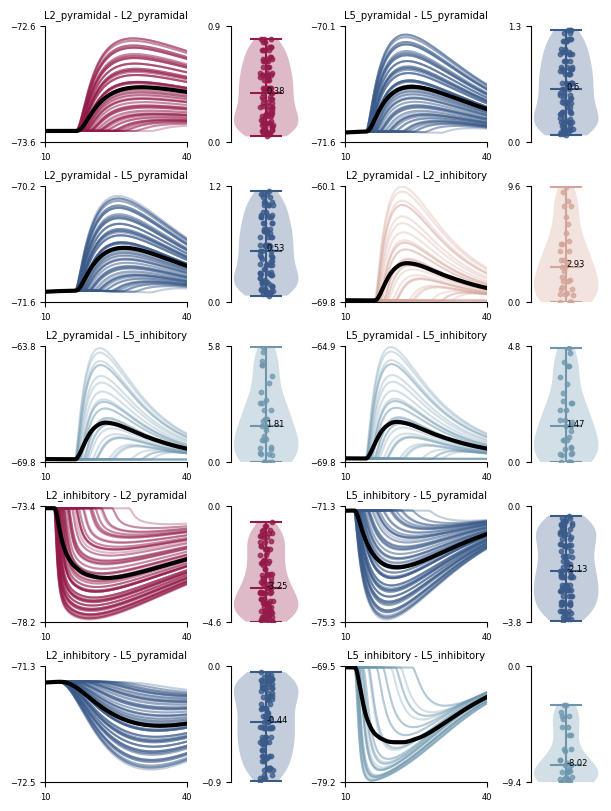

In [14]:
net_no_stim = duecker_ET_model()
dpl = simulate_dipole(net_no_stim, tstop=40, dt=0.05, bsl_cor="duecker", record_vsec="soma")


def get_psp(src_cell, trgt_cell, ampl, tsamp):
    net = duecker_ET_model()
    g = net_no_stim.gid_ranges[src_cell][int(len(net_no_stim.gid_ranges[src_cell]) / 2)]
    psp_gid = np.setdiff1d(net.gid_ranges[trgt_cell], g)

    num_sweeps = len(net.gid_ranges[trgt_cell])
    if src_cell == trgt_cell:
        num_sweeps -= 1
    psp = np.zeros((num_sweeps, 1))
    v_mem = np.zeros((num_sweeps, tsamp))

    net.add_tonic_bias(cell_type=src_cell, gid=g, bias_name="tonic_soma", amplitude=ampl, t0=10, tstop=15)
    simulate_dipole(net, tstop=40, dt=0.05, bsl_cor="duecker", record_vsec="soma")

    for ei, e in enumerate(psp_gid):
        v = np.array(net.cell_response.vsec[0][e]["soma"])
        bsl = np.array(net_no_stim.cell_response.vsec[0][e]["soma"])
        psp[ei] = np.max(np.abs(v - bsl))
        v_mem[ei] = v
    return psp, v_mem


fig, ax = plt.subplots(5, 4, figsize=(6, 8), constrained_layout=True, width_ratios=[1, 0.5, 1, 0.5])
ax = ax.flatten()
src_cells = ["L2_pyramidal", "L5_pyramidal", "L2_pyramidal", "L2_pyramidal", "L2_pyramidal", "L5_pyramidal", "L2_inhibitory", "L5_inhibitory", "L2_inhibitory", "L5_inhibitory"]
trgt_cells = ["L2_pyramidal", "L5_pyramidal", "L5_pyramidal", "L2_inhibitory", "L5_inhibitory", "L5_inhibitory", "L2_pyramidal", "L5_pyramidal", "L5_pyramidal", "L5_inhibitory"]
neuron_cols = {"L2_inhibitory": '#d4a498', "L2_pyramidal": '#941a49', "L5_inhibitory": '#6e97ae', "L5_pyramidal": '#3a5a8a'}

aidx = 0
for src, trgt in zip(src_cells, trgt_cells):
    if src == "L5_pyramidal":
        ampl = 3
    elif src == "L2_pyramidal":
        ampl = 1
    elif src == "L2_inhibitory":
        ampl = 0.5

    psp, vmem = get_psp(src_cell=src, trgt_cell=trgt, ampl=ampl, tsamp=len(dpl[0].times))
    ax[aidx].plot(dpl[0].times, vmem.T, color=neuron_cols[trgt], alpha=0.3)
    ax[aidx].plot(dpl[0].times, vmem.mean(axis=0), color='k', linewidth=3)
    ax[aidx].spines['top'].set_visible(False)
    ax[aidx].spines['right'].set_visible(False)
    ax[aidx].set_ylim([np.round(vmem.min() - 0.1, 1), np.round(vmem.max() + 0.1, 1)])
    ax[aidx].set_yticks([np.round(vmem.min(), 1) - 0.1, np.round(vmem.max() + 0.1, 1)])
    ax[aidx].set_xlim([10, 40])
    ax[aidx].set_xticks([10, 40])
    ax[aidx].set_title(f'{src} - {trgt}')
    aidx += 1

    if src == 'L5_pyramidal' or src == 'L2_pyramidal':
        pmin = 0
        pmax = np.round(psp.max() + 0.1, 1)
    else:
        psp *= -1
        pmin = np.round(psp.min() - 0.01, 1)
        pmax = 0
    v = ax[aidx].violinplot(psp, showmedians=True)
    v['bodies'][0].set_alpha(0.3)
    v['bodies'][0].set_facecolor(neuron_cols[trgt])
    v['cbars'].set_color(neuron_cols[trgt])
    v['cmaxes'].set_color(neuron_cols[trgt])
    v['cmins'].set_color(neuron_cols[trgt])
    v['cmedians'].set_color(neuron_cols[trgt])
    ax[aidx].scatter(np.random.uniform(0.95, 1.05, len(psp)), psp, s=10, alpha=0.75, c=neuron_cols[trgt])
    ax[aidx].text(1, np.median(psp), np.round(np.median(psp), 2))
    ax[aidx].spines['top'].set_visible(False)
    ax[aidx].spines['right'].set_visible(False)
    ax[aidx].spines['bottom'].set_visible(False)
    ax[aidx].set_xticks([])
    ax[aidx].set_ylim([pmin, pmax])
    ax[aidx].set_yticks([pmin, pmax])
    aidx += 1

fig.savefig(figpth / 'psp_plots.png')
fig.savefig(figpth / 'psp_plots.pdf')
plt.show()

## Not in manuscript - spike raster when driving one cell type

Drive each cell type in turn with a brief tonic bias and show the resulting
network spike raster.

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(20, 4), height_ratios=[0.05, 1], sharex=True)

cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
for i, c in enumerate(cell_types):
    # stimulate one cell type
    net = duecker_ET_model()
    net.set_cell_positions(inplane_distance=30.)

    ampl = 3.
    t0 = 10
    net.add_tonic_bias(cell_type=c, section='soma', bias_name='tonic_soma', amplitude=ampl, t0=t0, tstop=t0 + 3)

    dpl = simulate_dipole(net, tstop=30, n_trials=1, bsl_cor="duecker")

    # clamp signal for plotting
    timevec = net.cell_response.times
    clamp = np.zeros_like(timevec)
    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))
            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

    ax[0, i].plot(timevec, clamp, color='k', linewidth=1.5)
    ax[0, i].set_ylabel('clamp (nA)')
    ax[0, i].set_title(f'{cell_types[i]}')
    ax[0, i].set_xlim([5, 25])
    ax[0, i].set_axis_off()

    I = np.array(net.cell_response.spike_gids[0]) < 270
    gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times).reshape(-1,)[I]
    colors = [assign_color(net, gid) for gid in gids]

    ax[1, i].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
    ax[1, i].set_ylabel('neuron index')
    ax[1, i].set_xlim([5, 25])
    ax[1, i].set_xticks(np.arange(5, 26, 10))
    ax[1, i].set_xlabel('time (ms)')
    ax[1, i].set_ylim([0, 270])
    ax[1, i].set_yticks([0, 35, 135, 170, 270])
    ax[1, i].invert_yaxis()

fig.tight_layout()
fig.savefig(figpth / 'new_model_inter_layer_exp.png', dpi=300)
fig.savefig(figpth / 'new_model_inter_layer_exp.pdf', dpi=300)
plt.show()